In [65]:
import numpy as np
import time
from gwlens import solver2d
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0)) 
    # equal-mass binary
y = (0.1, 0.2)
#ws = np.linspace(0.5, 300, 1000)
ws = 10
t = time.perf_counter()
y1 = np.linspace(-1.5, 1.5, 100)
y2 = np.linspace(-1.5, 1.5, 100)
Z = np.empty((len(y2), len(y1)))          # note: rows are y2, columns are y1

for j, b in enumerate(y2):
    for i, a in enumerate(y1):
        F = solver2d.amplification(ws, (a, b), lens)
        Z[j, i] = np.abs(F)            # iw = index of your chosen w

plt.pcolormesh(y1, y2, Z, cmap='magma')
plt.contourf(y1, y2, Z, levels=50, linewidths=0.5)
plt.colorbar(label='|F|')
plt.xlabel('y1')
plt.ylabel('y2')


KeyboardInterrupt: 

SIE (q=0.7) + external shear         analytic check 5.1e-10 | 1000 frequencies, |F| from 1.078 to 7.183 | self-check worst 3.5e-13 | 6.8 s incl. self-check
pseudo-elliptical NFW                analytic check 6.1e-10 | 1000 frequencies, |F| from 0.557 to 3.053 | self-check worst 3.4e-13 | 0.2 s incl. self-check
cored halo + 3 point-mass subhalos   analytic check 5.4e-10 | 1000 frequencies, |F| from 0.085 to 3.772 | self-check worst 9.0e-12 | 0.4 s incl. self-check


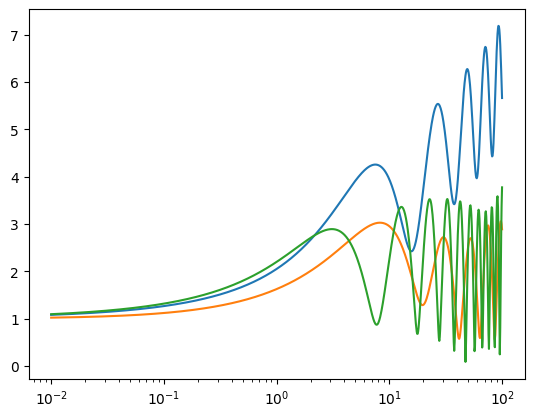

In [ ]:
"""
Defining your own lens for lens2d_general.py: three worked examples.

Recipe
  1. write psi(x1, x2) with analytic numpy operations (it is also called with complex arrays)
  2. list the points where psi is not smooth (point masses, cusps, very small cores)
  3. lens = G.Lens(psi, singular=[...])            # optional: q_inf = kappa + |gamma|
  4. F = G.amplification_many(ws, y, lens)          # or G.amplification(w, y, lens)
     F, err = G.amplification_many(ws, y, lens, estimate_error=True)   # self-check
"""
import time
import numpy as np
from gwlens import solver2d
import matplotlib.pyplot as plt


# ---------------------------------------------------------------- 1. SIE + external shear
def sie_plus_shear(b=1.0, q=0.7, phi=0.3, gamma1=0.05, gamma2=-0.03, x0=(0.0, 0.0)):
    """Singular isothermal ellipsoid (Keeton & Kochanek form) rotated by phi, plus external shear."""
    c, s, sq = np.cos(phi), np.sin(phi), np.sqrt(1 - q * q)
    a1, a2 = x0

    def psi(x1, x2):
        u = c * (x1 - a1) + s * (x2 - a2)                 # coordinates along the ellipse axes
        v = -s * (x1 - a1) + c * (x2 - a2)
        om = np.sqrt(q * q * u * u + v * v)
        ax = b * q / sq * np.arctan(sq * u / om)
        ay = b * q / sq * np.arctanh(sq * v / om)
        return u * ax + v * ay + 0.5 * (gamma1 * (x1 * x1 - x2 * x2) + 2 * gamma2 * x1 * x2)
    return solver2d.Lens(psi, singular=[x0], q_inf=np.hypot(gamma1, gamma2))


# ---------------------------------------------------------------- 2. pseudo-elliptical NFW
def elliptical_nfw(k=2.0, psi0=1.0, e=0.15):
    """NFW potential evaluated at an elliptical radius (pseudo-elliptical NFW)."""
    def psi(x1, x2):
        R = np.sqrt((1 - e) * x1 * x1 + (1 + e) * x2 * x2 + 0j)
        v = k * R
        return 0.5 * psi0 * (np.log(v / 2)**2 + np.arccos(1 / v)**2)
    return solver2d.Lens(psi, singular=[(0.0, 0.0)])


# ---------------------------------------------------------------- 3. host halo + subhalos (built from components)
def host_with_subhalos():
    host = solver2d.cis(psi0=1.0, rc=0.1)
    subs = [(0.01, (1.2, 0.3)), (0.005, (-0.8, 0.9)), (0.02, (0.4, -1.1))]
    lens = host
    for m, pos in subs:
        lens = lens + solver2d.point_mass(m, pos)
    return lens


if __name__ == "__main__":
    ws = np.logspace(-2, 2, 1000)
    for name, lens, y in (("SIE (q=0.7) + external shear", sie_plus_shear(), (0.15, 0.1)),
                          ("pseudo-elliptical NFW", elliptical_nfw(), (0.2, 0.1)),
                          ("cored halo + 3 point-mass subhalos", host_with_subhalos(), (0.3, 0.2))):
        mism = lens.check_analytic()
        t = time.perf_counter()
        F, err = solver2d.amplification_many(ws, y, lens, estimate_error=True)
        dt = time.perf_counter() - t
        print(f"{name:<36} analytic check {mism:.1e} | {ws.size} frequencies, |F| from {abs(F).min():.3f} to {abs(F).max():.3f}"
              f" | self-check worst {err.max():.1e} | {dt:.1f} s incl. self-check", flush=True)
        plt.semilogx(ws,np.abs(F),label=f"{}")
        plt.legend()

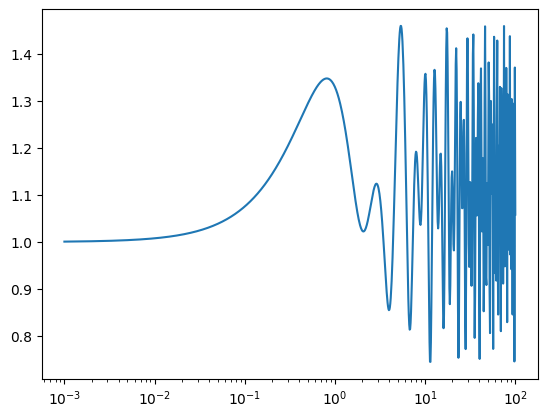

In [37]:
w = np.logspace(-3, 2, 1000)
lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0))  

lens_cis = solver2d.cis() + solver2d.cis()
plt.semilogx(w, np.abs(solver2d.amplification_many(w, (1.1, 0.2), lens)), label="binary point masses")


many w : 5000 frequencies at one y          0.07 s
many y : 40000 source positions at one w    0.06 s
sampler: one solver, 3 new y x 5000 frequencies    0.14 s


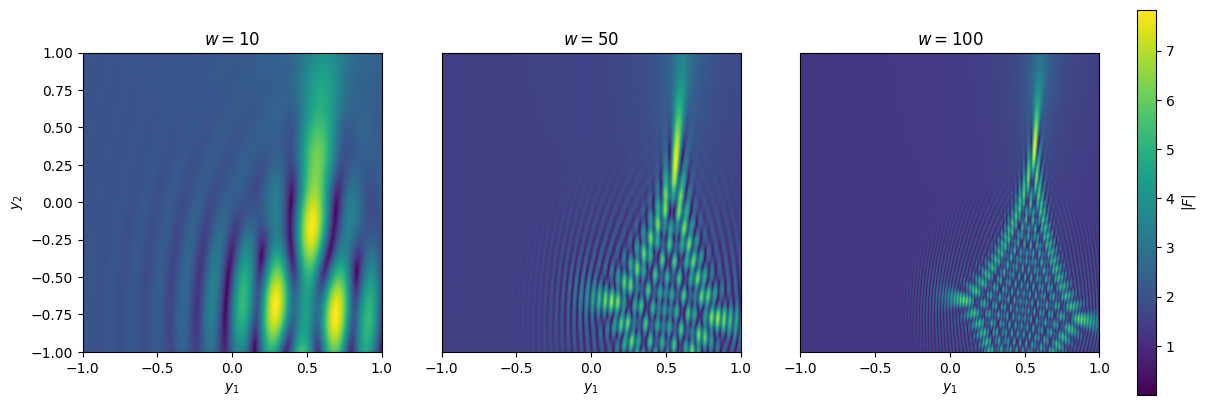

In [ ]:
import numpy as np
from gwlens import solver2d
import matplotlib.pyplot as plt


x = np.linspace(-1.0, 1.0, 1000)
Y1, Y2 = np.meshgrid(x, x)


norm = 1
pos1 = 2.0
pos2 = 2.0

#lens_cis = solver2d.cis(norm,0.05,(0,0)) + solver2d.cis(norm,0.05,(pos1,pos2))+solver2d.cis(norm,0.05,(-pos1,pos2)) + solver2d.cis(norm,0.05,(pos1,-pos2))+solver2d.cis(norm,0.05,(-pos1,-pos2)) 


w_values = [10, 50, 100]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, w in zip(axes, w_values):
    Fm = solver2d.amplification_map(w, Y1, Y2, lens)

    im = ax.imshow(
        np.abs(Fm),
        extent=(-1, 1, -1, 1),
        origin="lower",
        cmap="viridis",
        aspect="equal"
    )

    ax.set_title(f"$w={w}$")
    ax.set_xlabel("$y_1$")
    ax.set_ylabel("$y_2$")

# One shared colorbar for all subplots
fig.colorbar(im, ax=axes, label="$|F|$", pad=0.03, shrink=1.0)
# Show y2 axis only on the leftmost subplot
for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params(axis="y", left=False, labelleft=False)

#plt.tight_layout()
plt.savefig("cis_map.png", dpi=300, bbox_inches="tight")
plt.show()

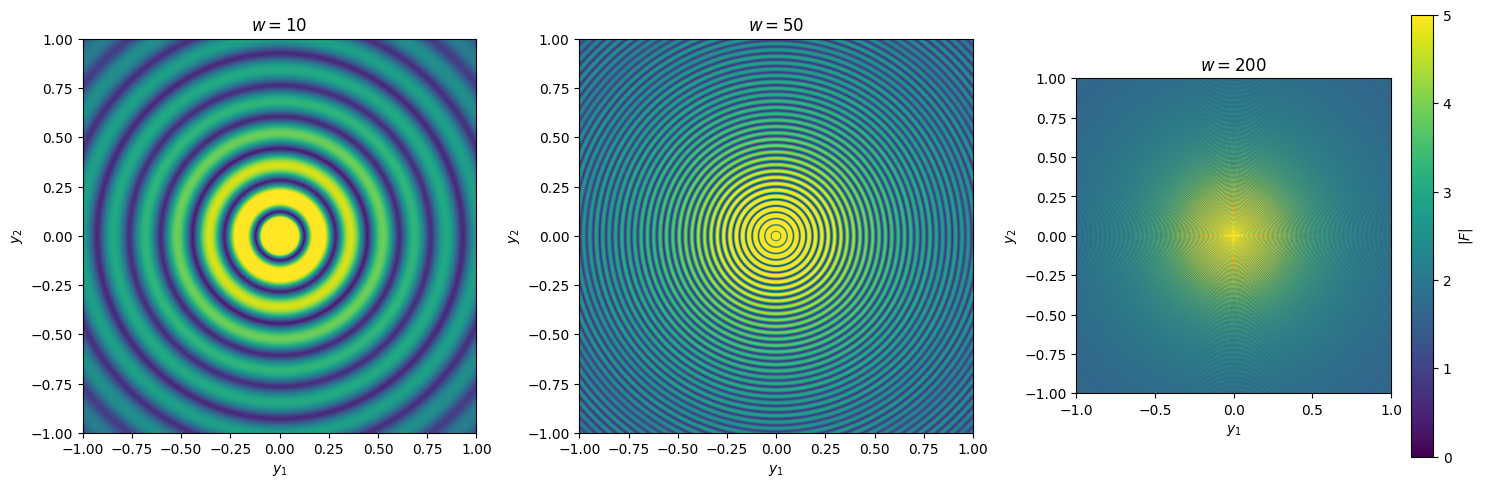

In [34]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1.0, 1.0, 1000)
Y1, Y2 = np.meshgrid(x, x)

w_values = [10, 50, 200]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use the same color scale for every subplot
vmin, vmax = 0, 5

for ax, w in zip(axes, w_values):
    Fm = solver2d.amplification_map(w, Y1, Y2, lens_cis)

    im = ax.imshow(
        np.abs(Fm),
        extent=(-1, 1, -1, 1),
        origin="lower",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"$w={w}$")
    ax.set_xlabel("$y_1$")
    ax.set_ylabel("$y_2$")



plt.colorbar(im,  label="$|F|$")

plt.tight_layout()
plt.savefig(fname="cis_map.png",dpi=300)

#plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1, 1, 500)
Y1, Y2 = np.meshgrid(x, x)

# Six values of w
w_values = [4,20,100] #np.logspace(1, 2, 6)
off = 2.0
#lens = point_mass(0.25, (-0.5, 0.0)) + point_mass(0.25, (0.5, 0.0))+ point_mass(0.25, (0.0, 0.5)) + point_mass(0.25, (0.0, -0.5))
lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
# Create 2 rows and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(15, 9))

for ax, w in zip(axes.flat, w_values):

    F = np.abs(amplification_map(w, Y1, Y2, lens))

    im = ax.imshow(
        F,
        extent=(-1, 1, -1, 1),
        cmap='inferno'
    )

    ax.set_title(f'$w = {w:.3g}$')
    ax.set_xlabel('$y_1$')
    ax.set_ylabel('$y_2$')

    fig.colorbar(im, ax=ax, label='$|F|$')

plt.tight_layout()
plt.suptitle('CIS')
plt.show()

NameError: name 'cis' is not defined

Text(0, 0.5, '|F|')

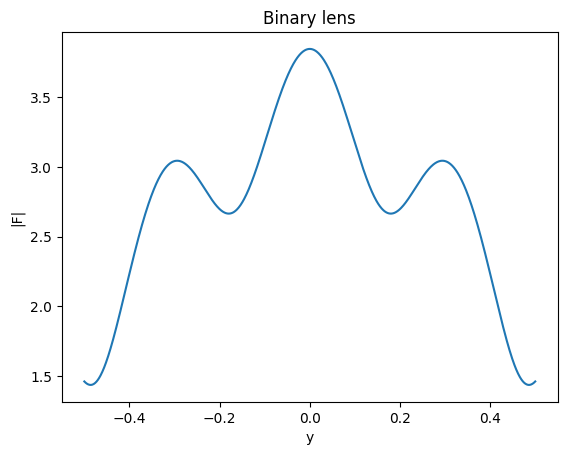

In [4]:
import matplotlib.pyplot as plt
w_val = np.linspace(0.1, 100, 1000)
y_val = np.linspace(-0.5, 0.5, 1000)
lens1  = point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
F_val = []
for i in y_val:
    F_val.append(amplification(10, (i,0), lens1))
plt.plot(y_val, np.abs(F_val))
plt.title('Binary lens')
plt.xlabel('y')
plt.ylabel('|F|')

Time taken for amplification_many: 0.11 seconds


Text(0, 0.5, '|F|')

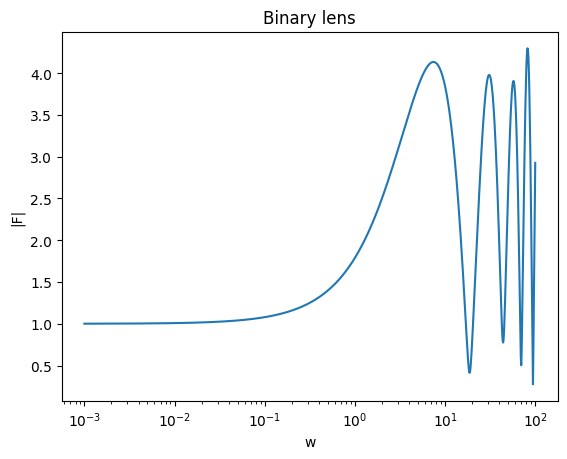

In [20]:
import time
w_val = np.logspace(-3, 2, 1000)
off =0.1
#lens = cis(psi0=1.0, rc=0.05, x0=(off, 0.0))+cis(psi0=1.0, rc=0.05, x0=(-off, 0))+cis(psi0=1.0, rc=0.05, x0=(0, off))+cis(psi0=1.0, rc=0.05, x0=(0.0, -off))
lens= point_mass(0.5, (-0.5, 0.0)) + point_mass(0.5, (0.5, 0.0))
start_time = time.time()
F = amplification_many(w_val, (0.0, 0.0), lens,n_workers=3)
end_time = time.time()
print(f"Time taken for amplification_many: {end_time - start_time:.2f} seconds")
plt.semilogx(w_val, np.abs(F))
plt.title('Binary lens')
plt.xlabel('w')
plt.ylabel('|F|')   


6.191142409331626
390.63094886502915


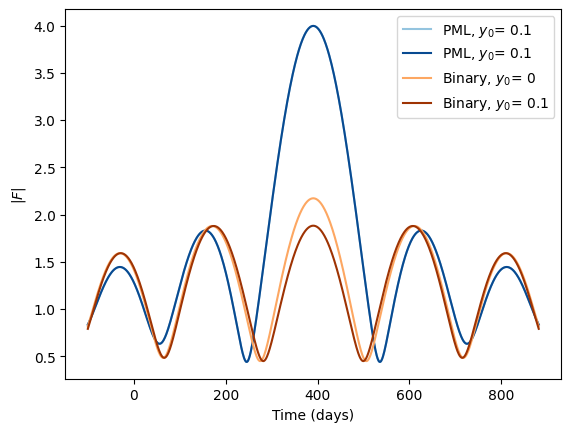

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver2d
from gwlens import microlensing
from scipy.constants import G, c



# Separate colormaps
pml_cmap = plt.get_cmap("Blues")
binary_cmap = plt.get_cmap("Oranges")



Dl = 10
Ds = 20
v = 200
M = 50
freq= 1000

SOLAR_MASS = 1.98892e30  
POINT_LENS_W_CONSTANT = 8 * np.pi * G * SOLAR_MASS / c ** 3

w = POINT_LENS_W_CONSTANT*M*freq
print(w)

TE = microlensing.EinsteinCrossingTime(Dl,Ds,v,M)
print(TE)
closest_approach = [0,0.1]

#for colors
colors = np.linspace(0.4, 0.9, len(closest_approach))

t0 = TE
t = np.linspace(0-100,2*TE+100,1000)
lens_pointmass = solver2d.point_mass(1.0,(0,0))
lens_binary= solver2d.point_mass(0.5,(-0.5,0)) + solver2d.point_mass(0.5,(0,0))


for i,y0_i in enumerate(closest_approach):



    y0 = y0_i
    #y = np.linspace(-2,2,1000)
    y = microlensing.MicrolensingImpactparameter(t,y0,t0,TE)

    F_pointmass = solver2d.amplification_map(w, y1 = 0, y2= y, lens=lens_pointmass)


    plt.plot(t,np.abs(F_pointmass), label=f"PML, $y_0$= {y0}", color=pml_cmap(colors[i]))

for i,y0_i in enumerate(closest_approach):
    y0 = y0_i

    y = microlensing.MicrolensingImpactparameter(t,y0,t0,TE)
    F_binary = solver2d.amplification_map(w, y1 = 0, y2= y, lens=lens_binary)
    plt.plot(t,np.abs(F_binary), label=f"Binary, $y_0$= {y0}",color= binary_cmap(colors[i]))

plt.xlabel("Time (days)")
plt.ylabel("$|F|$")
plt.legend()




# Plots for the paper
# Idea is to have a comparison plot between GWLENS and GLoW for 6 different axis-symmetric lens models
# Keep one cmap for GLoW and another one for GWLENS
# If possible attach a bench marking timeit module along with it with a set of n-repeat option.



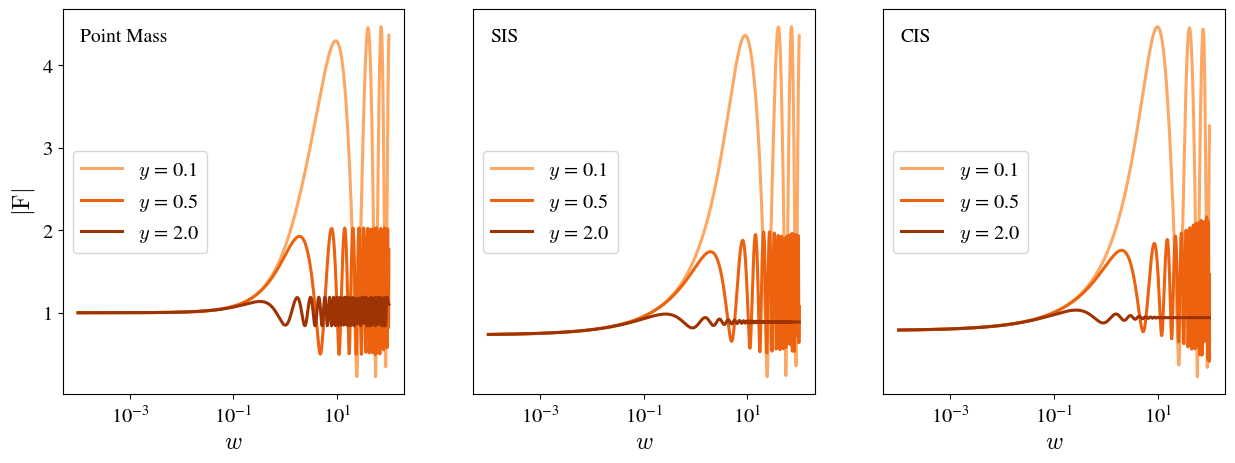

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver1d
from gwlens.tools import plotting

#Uncomment below if Latex works
plotting.apply_figure_style()
plt.rcParams.update({
'text.usetex': False})


glow_cmap = plt.get_cmap("Blues")
gwlens_cmap = plt.get_cmap("Oranges")


ws = np.logspace(-4,2,1000)
y_values = [0.1,0.5,2.0]

colors = np.linspace(0.4, 0.9, len(y_values))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

lens_pml = solver1d.point_mass()
lens_sis = solver1d.sis()
lens_cis = solver1d.cis()

lens_nfw = solver1d.nfw()
lens_powerlaw = solver1d.power_law()
#lens_plummer = solver1d.plummer()

lens = [lens_pml, lens_sis, lens_cis]
lens_names = ["Point Mass", "SIS", "CIS"]

for ax, lens_model, lens_name in zip(axes, lens,lens_names):

    for i,y_i in enumerate(y_values):
        F = solver1d.amplification_many(ws,y_i,lens_model,n_workers=1)

        ax.semilogx(ws,np.abs(F),label=f"$y$ = {y_i}",c=gwlens_cmap(colors[i]), linewidth=2.2)
    
    # Add lens name inside the subplot
    ax.text( 0.05, 0.95, lens_name, transform=ax.transAxes, fontsize=14, fontweight="normal", ha="left", va="top" )
    ax.legend()
    ax.set_xlabel('$w$')
    ax.set_ylabel('$|\\mathrm{F}|$')

for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params(axis="y", left=False, labelleft=False)
        



In [ ]:
from glow import lenses, time_domain_c, freq_domain_c

glow_nfw_Psi = lenses.Psi_NFW(p_phys={'name':'NFW','psi0':1.0,'xs':1/rs})
glow_cis_Psi = lenses.Psi_CIS(p_phys={})


time_domain_c.It_SingleIntegral(Psi,y= y_i)
Fw = freq_domain_c.Fw_FFT_C(It)


ModuleNotFoundError: No module named 'glow'

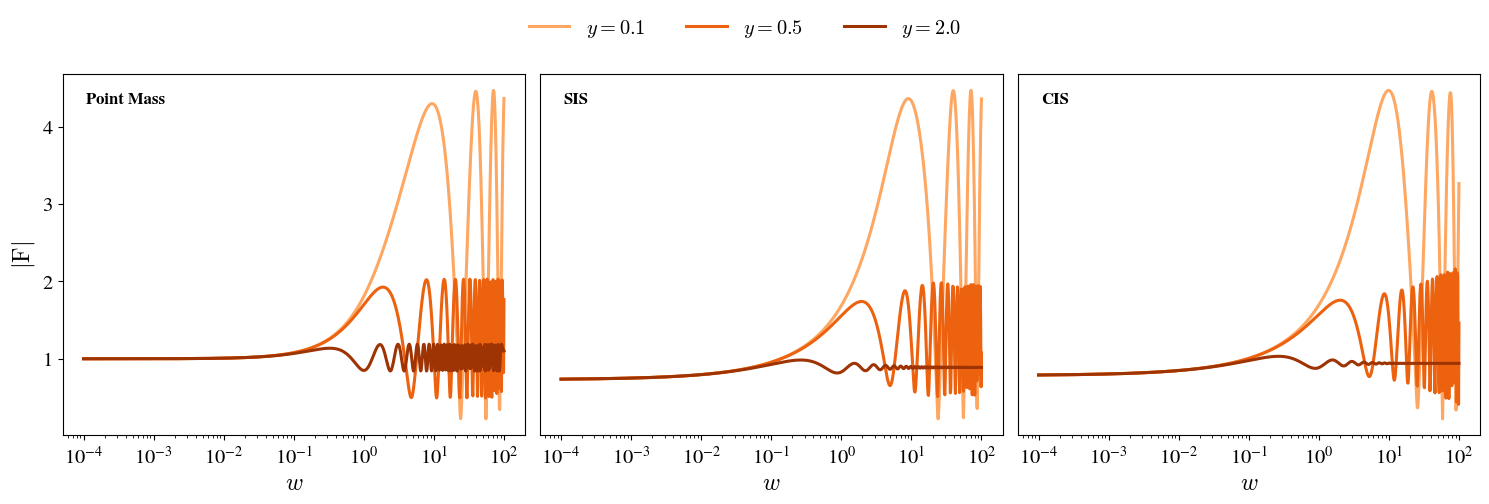

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver1d
from gwlens.tools import plotting

# Apply figure style
# Uncomment or modify if LaTeX is available
plotting.apply_figure_style()
plt.rcParams.update({
    'text.usetex': False
})

# Colormaps
glow_cmap = plt.get_cmap("Blues")
gwlens_cmap = plt.get_cmap("Oranges")

# Frequency and source position values
ws = np.logspace(-4, 2, 1000)
y_values = [0.1, 0.5, 2.0]

# Colors corresponding to each y value
colors = np.linspace(0.4, 0.9, len(y_values))

# Create figure and subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Define lens models
lens_pml = solver1d.point_mass()
lens_sis = solver1d.sis()
lens_cis = solver1d.cis()

lens_nfw = solver1d.nfw()
lens_powerlaw = solver1d.power_law()
# lens_plummer = solver1d.plummer()

# Select lens models to plot
lens = [lens_pml, lens_sis, lens_cis]

# Names displayed inside each subplot
lens_names = ["Point Mass", "SIS", "CIS"]

# Loop over lens models
for ax, lens_model, lens_name in zip(axes, lens, lens_names):

    # Plot amplification for each y value
    for i, y_i in enumerate(y_values):

        F = solver1d.amplification_many(
            ws,
            y_i,
            lens_model,
            n_workers=1
        )

        ax.semilogx( ws,np.abs(F),label=fr"$y = {y_i}$", color=gwlens_cmap(colors[i]),linewidth=2.2  )

    # Add lens name inside the subplot
    ax.text(
        0.05, 0.95,
        lens_name,
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="top"
    )

    # Axis labels
    ax.set_xlabel(r"$w$")
    ax.set_ylabel(r"$|\mathrm{F}|$")

# Remove repeated y-axis labels from second and third subplots
for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params(
        axis="y",
        left=False,
        labelleft=False
    )

# Create one shared legend using the first subplot's line labels
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(y_values),
    frameon=False
)

# Adjust layout to leave room for the legend
fig.tight_layout(rect=[0, 0, 1, 0.90])

# Display the figure
plt.show()

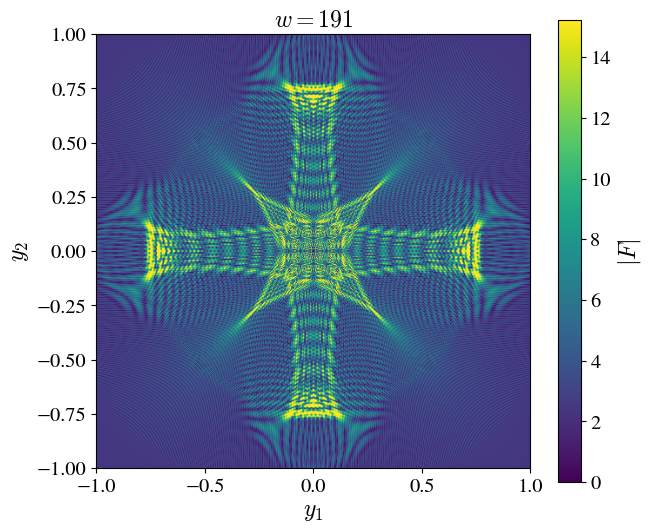

In [70]:
import numpy as np
from gwlens import solver2d
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

x = np.linspace(-1.0, 1.0, 500)
Y1, Y2 = np.meshgrid(x, x)

norm = 1
pos1 = 2.0
pos2 = 2.0

# Define your lens
# lens = solver2d.cis(norm, 0.05, (0, 0)) + ...

# Frequencies from 1 to 200
w_values = np.arange(1, 201, 10)


norm = 1
pos1 = 2.0
pos2 = 2.0

lens = solver2d.cis(norm,0.05,(0,0)) + solver2d.cis(norm,0.05,(pos1,pos2))+solver2d.cis(norm,0.05,(-pos1,pos2)) + solver2d.cis(norm,0.05,(pos1,-pos2))+solver2d.cis(norm,0.05,(-pos1,-pos2)) 

#lens = solver2d.point_mass(0.5, (-0.5, 0.0)) + solver2d.point_mass(0.5, (0.5, 0.0)) 
# Calculate the initial amplification map
Fm = solver2d.amplification_map(w_values[0], Y1, Y2, lens)

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    np.abs(Fm),
    extent=(-1, 1, -1, 1),
    origin="lower",
    cmap="viridis",
    aspect="equal",
    animated=True
)

# Keep the color scale fixed throughout the animation
im.set_clim(0, np.max(np.abs(Fm)))

cbar = fig.colorbar(im, ax=ax, label=r"$|F|$")
title = ax.set_title(rf"$w={w_values[0]}$")
ax.set_xlabel(r"$y_1$")
ax.set_ylabel(r"$y_2$")


def update(frame):
    w = w_values[frame]

    Fm = solver2d.amplification_map(w, Y1, Y2, lens)

    im.set_data(np.abs(Fm))
    title.set_text(rf"$w={w}$")

    return im, title


ani = FuncAnimation(
    fig,
    update,
    frames=len(w_values),
    interval=100,
    blit=False
)

# Save as GIF
ani.save("cis_map.gif", writer=PillowWriter(fps=5))

plt.show()